# 04 — Jeux de labels : comparaison + gold

Les CSV de `data/labels/` (hors cache LLM) sont des **candidats d'entraînement**.
Les **58 gold** de `data/csv/train.csv` (12 cibles toutes renseignées) ne servent
**jamais** à piloter le checkpoint — uniquement à comparer la qualité des labels.

Ce notebook :

1. Inventorie tous les CSV du dossier
2. Compare couverture / prévalence / accord entre jeux
3. Mesure chaque jeu **sur les gold** (AUC, F1, fidélité, MAE) + graphiques

Pipeline historique (lexique) : `pseudo_labels.csv` → masquage / plafond →
`train_val_labels.csv` (sans gold). Les CSV LLM (`labels_llm_gpt56sol.csv`,
`llm_labels_v4_blend.csv`, …) peuvent contenir les 58 gold : le loader les
exclut quand même au train (`_exclude_gold`).
Tout nouveau CSV déposé dans `data/labels/` est pris en compte au rerun.
`report_labels_gpt56sol.csv` a les mêmes labels que `labels_llm_gpt56sol.csv` (plus des colonnes de confiance) — le notebook le signale comme doublon.


In [7]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import f1_score, roc_auc_score

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.nlp.lexicon import TARGETS

LABELS_DIR = ROOT / 'data' / 'labels'
TRAIN_CSV = ROOT / 'data' / 'csv' / 'train.csv'

plt.rcParams.update({
    'figure.dpi': 110,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'axes.axisbelow': True,
})
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)
pd.set_option('display.max_colwidth', 48)

# Optionnel : restreindre / ignorer des fichiers (noms de fichiers, pas chemins)
INCLUDE = []   # ex. ['labels_llm_gpt56sol.csv', 'llm_labels_v4_blend.csv']
EXCLUDE = []   # ex. ['report_labels_gpt56sol.csv']  # doublon de gpt56sol + colonnes conf


def conf_col(df: pd.DataFrame, t: str) -> str | None:
    for name in (f'{t}_conf', f'{t}__conf'):
        if name in df.columns:
            return name
    return None


def load_label_csv(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path)
    rename = {}
    for t in TARGETS:
        alt = f'{t}__conf'
        if alt in df.columns and f'{t}_conf' not in df.columns:
            rename[alt] = f'{t}_conf'
    return df.rename(columns=rename) if rename else df


def has_targets(df: pd.DataFrame) -> bool:
    return 'StudyInstanceUID' in df.columns and all(t in df.columns for t in TARGETS)


def is_binary_labels(df: pd.DataFrame) -> bool:
    vals = pd.to_numeric(df[TARGETS].stack(), errors='coerce').dropna()
    if vals.empty:
        return True
    return bool(((vals == 0) | (vals == 1)).all())


train_df = pd.read_csv(TRAIN_CSV)
gold_df = train_df[train_df[TARGETS].notna().all(axis=1)].copy()
GOLD_UIDS = gold_df['StudyInstanceUID']
gold_y = gold_df.set_index('StudyInstanceUID')[TARGETS]
print(f'gold : {len(gold_df)} études  |  corpus train.csv : {len(train_df)}')

paths = sorted(LABELS_DIR.glob('*.csv'))
if INCLUDE:
    paths = [p for p in paths if p.name in INCLUDE]
paths = [p for p in paths if p.name not in EXCLUDE]

sets: dict[str, pd.DataFrame] = {}
for p in paths:
    df = load_label_csv(p)
    if not has_targets(df):
        print(f'ignoré (colonnes cibles manquantes) : {p.name}')
        continue
    if df['StudyInstanceUID'].duplicated().any():
        n = int(df['StudyInstanceUID'].duplicated().sum())
        print(f'{p.name} : {n} UID dupliqués, on garde la 1re ligne')
        df = df.drop_duplicates('StudyInstanceUID', keep='first')
    sets[p.stem] = df.reset_index(drop=True)

print(f'{len(sets)} jeux chargés :', ', '.join(sets))


gold : 58 études  |  corpus train.csv : 4407
8 jeux chargés : gold_nlp_predictions, labels_llm_gpt56sol, llm_gold_gemini-3.7-flash, llm_labels_v4_blend, llm_pseudo_labels, pseudo_labels, report_labels_gpt56sol, train_val_labels


## Inventaire

Pour chaque CSV : taille, recouvrement gold, type de valeurs (binaire 0/1 vs soft),
couverture moyenne, prévalence moyenne, colonne `split` / `lang` / confiances.


In [8]:
rows = []
for name, df in sets.items():
    n_gold = int(df['StudyInstanceUID'].isin(GOLD_UIDS).sum())
    binary = is_binary_labels(df)
    vals = pd.to_numeric(df[TARGETS].stack(), errors='coerce')
    uniq = sorted(vals.dropna().unique().tolist())
    rows.append({
        'jeu': name,
        'n': len(df),
        'n_gold': n_gold,
        'type': 'binaire' if binary else 'soft',
        'n_valeurs': len(uniq),
        'couverture': float(df[TARGETS].notna().mean().mean()),
        'prevalence': float(df[TARGETS].mean().mean()),
        'full_na': int(df[TARGETS].isna().all(axis=1).sum()),
        'split': 'split' in df.columns,
        'lang': 'lang' in df.columns,
        'conf': any(conf_col(df, t) for t in TARGETS),
    })
inv = pd.DataFrame(rows).sort_values(['n_gold', 'n'], ascending=False)
display(inv.round(3))

# Doublons exacts de labels (mêmes UID, mêmes 12 cibles)
stems = list(sets)
for i, a in enumerate(stems):
    for b in stems[i + 1:]:
        da, db = sets[a], sets[b]
        if set(da.StudyInstanceUID) != set(db.StudyInstanceUID):
            continue
        m = da.merge(db, on='StudyInstanceUID', suffixes=('_a', '_b'))
        same = all(np.allclose(m[f'{t}_a'].fillna(-9), m[f'{t}_b'].fillna(-9)) for t in TARGETS)
        if same:
            print(f'doublon de labels : {a}  ==  {b}')


,jeu,n,n_gold,type,n_valeurs,couverture,prevalence,full_na,split,lang,conf
1,labels_llm_gpt56sol,4407,58,soft,32,1.000,0.261,0,False,False,False
3,llm_labels_v4_blend,4407,58,soft,211,1.000,0.338,0,False,False,False
6,report_labels_gpt56sol,4407,58,soft,32,1.000,0.261,0,False,False,True
0,gold_nlp_predictions,58,58,binaire,2,0.476,0.688,0,False,True,True
2,llm_gold_gemini-3.7-flash,57,57,binaire,2,0.751,0.570,0,False,True,True
5,pseudo_labels,4349,0,binaire,2,0.380,0.543,187,False,True,True
7,train_val_labels,4349,0,binaire,2,0.363,0.469,202,True,True,False
4,llm_pseudo_labels,2359,0,binaire,2,0.770,0.371,32,False,True,True


doublon de labels : labels_llm_gpt56sol  ==  report_labels_gpt56sol


## Couverture et prévalence

Prévalences **sur tout le fichier** (populations différentes : 4 349 sans gold vs 4 407
avec gold vs 58 gold-only) — à lire avec `n` et `n_gold` de l'inventaire.

Le graphique de droite compare les prévalences **sur les 58 gold** (même population)
avec la prévalence gold en référence.


Couverture moyenne par jeu


,gold_nlp_predictions,labels_llm_gpt56sol,llm_gold_gemini-3.7-flash,llm_labels_v4_blend,llm_pseudo_labels,pseudo_labels,report_labels_gpt56sol,train_val_labels
couverture,0.476,1.0,0.751,1.0,0.77,0.38,1.0,0.363


Prévalence moyenne (fichier entier)


,gold_nlp_predictions,labels_llm_gpt56sol,llm_gold_gemini-3.7-flash,llm_labels_v4_blend,llm_pseudo_labels,pseudo_labels,report_labels_gpt56sol,train_val_labels
prevalence,0.688,0.261,0.57,0.338,0.371,0.543,0.261,0.469


Prévalence sur le recouvrement gold (NaN ignorés)


,GOLD,gold_nlp_predictions,labels_llm_gpt56sol,llm_gold_gemini-3.7-flash,llm_labels_v4_blend,report_labels_gpt56sol
ACL,0.414,0.610,0.485,0.528,0.525,0.485
MCL,0.155,0.393,0.278,0.320,0.317,0.278
Medial Meniscus,0.448,0.727,0.474,0.519,0.532,0.474
Lateral Meniscus,0.397,0.600,0.355,0.449,0.453,0.355
Medial OA,0.259,0.786,0.355,0.476,0.412,0.355
Lateral OA,0.190,0.769,0.293,0.444,0.385,0.293
PF OA,0.362,0.364,0.423,0.545,0.471,0.423
Effusion,0.603,0.898,0.872,0.909,0.829,0.872
Synovitis,0.466,1.000,0.293,1.000,0.496,0.293
Baker's,0.207,0.600,0.279,0.593,0.401,0.279


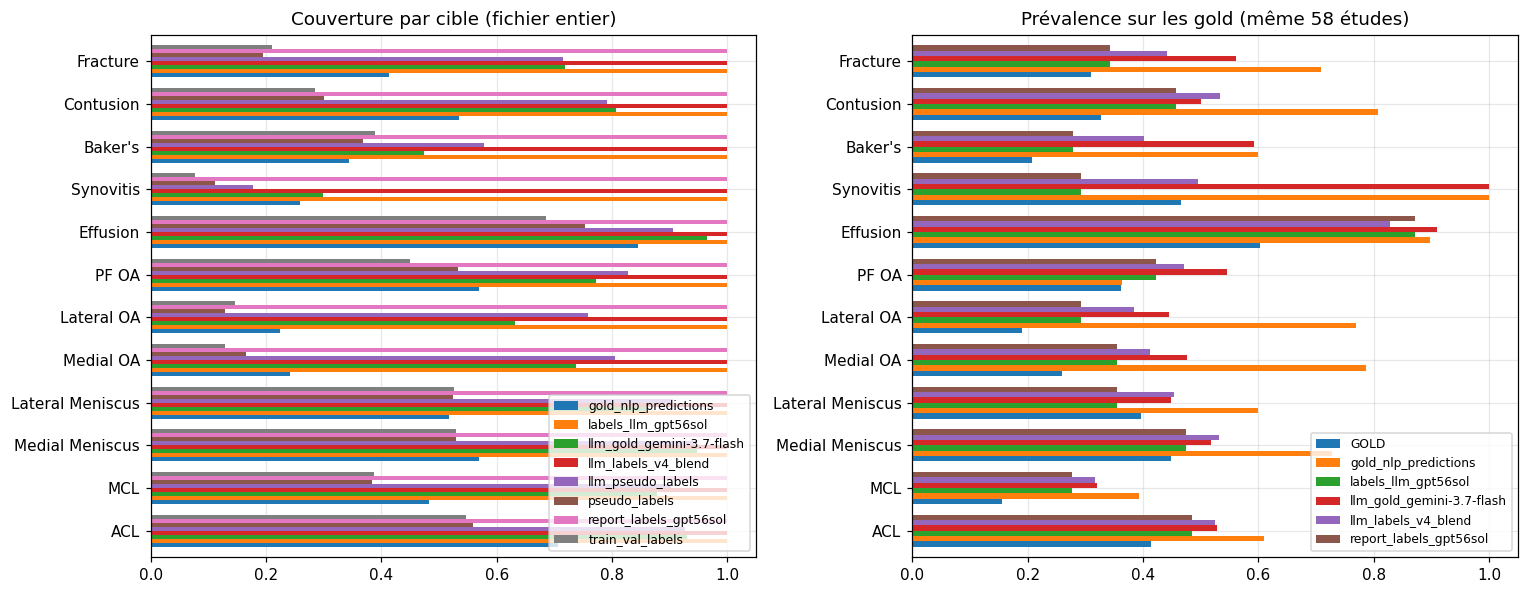

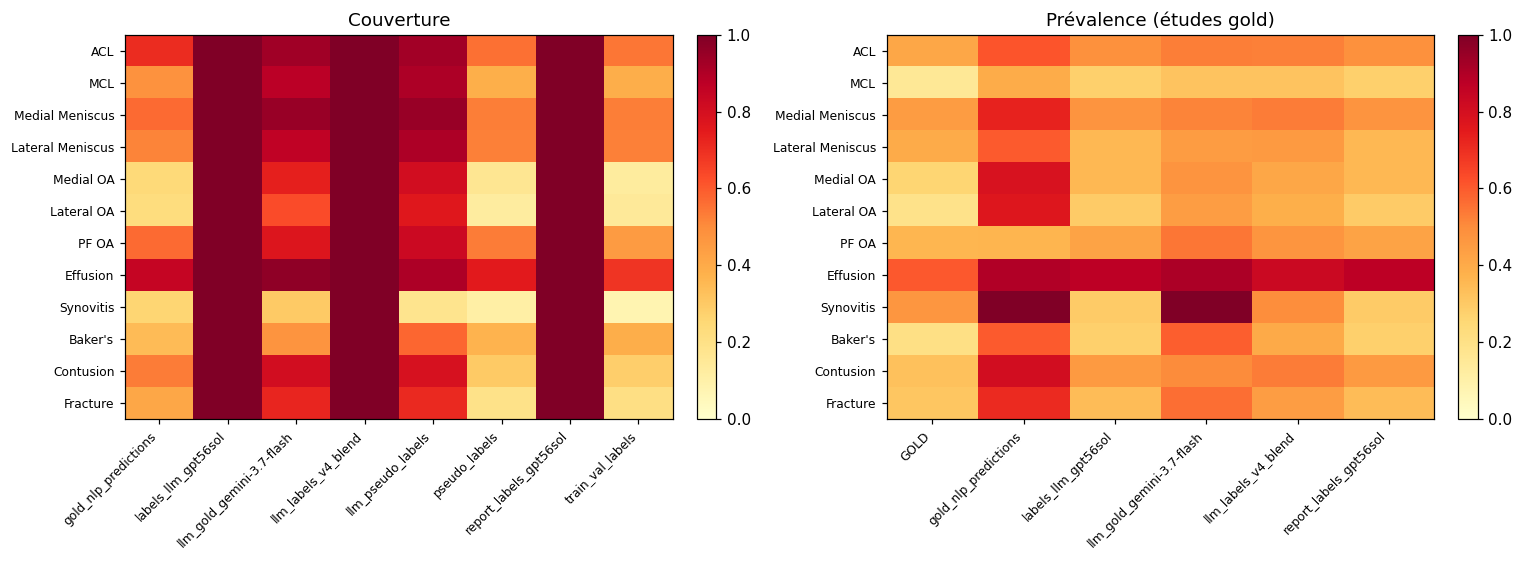

In [9]:
cov = pd.DataFrame({name: df[TARGETS].notna().mean() for name, df in sets.items()})
prev_all = pd.DataFrame({name: df[TARGETS].mean() for name, df in sets.items()})

gold_sets = {n: df[df.StudyInstanceUID.isin(GOLD_UIDS)] for n, df in sets.items()
             if df.StudyInstanceUID.isin(GOLD_UIDS).any()}
prev_gold = pd.DataFrame({name: df[TARGETS].mean() for name, df in gold_sets.items()})
prev_gold.insert(0, 'GOLD', gold_y.mean())

print('Couverture moyenne par jeu')
display(cov.mean().rename('couverture').to_frame().T.round(3))
print('Prévalence moyenne (fichier entier)')
display(prev_all.mean().rename('prevalence').to_frame().T.round(3))
print('Prévalence sur le recouvrement gold (NaN ignorés)')
display(prev_gold.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
cov.plot.barh(ax=axes[0], width=0.75)
axes[0].set_title('Couverture par cible (fichier entier)')
axes[0].set_xlim(0, 1.05)
axes[0].legend(loc='lower right', fontsize=8)

prev_gold.plot.barh(ax=axes[1], width=0.75)
axes[1].set_title('Prévalence sur les gold (même 58 études)')
axes[1].set_xlim(0, 1.05)
axes[1].legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()

# Heatmaps
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for ax, mat, title, vmin, vmax in (
    (axes[0], cov, 'Couverture', 0, 1),
    (axes[1], prev_gold, 'Prévalence (études gold)', 0, 1),
):
    im = ax.imshow(mat.values, aspect='auto', cmap='YlOrRd', vmin=vmin, vmax=vmax)
    ax.set_xticks(range(mat.shape[1]))
    ax.set_xticklabels(mat.columns, rotation=45, ha='right', fontsize=8)
    ax.set_yticks(range(mat.shape[0]))
    ax.set_yticklabels(mat.index, fontsize=8)
    ax.set_title(title)
    ax.grid(False)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


## Accord entre jeux (études communes)

MAE sur les cellules renseignées des deux côtés, après alignement UID.
Les jeux **identiques** apparaissent en ~0. Les soft vs binaire sont pénalisés
même s'ils classent pareil au seuil 0.5 — d'où la 2e matrice (accord binarisé).


,jeu_a,jeu_b,n_etudes,n_cellules,MAE,accord_0.5
8,labels_llm_gpt56sol,report_labels_gpt56sol,4407,52884,0.000,1.000
20,pseudo_labels,train_val_labels,4349,18258,0.000,1.000
11,llm_gold_gemini-3.7-flash,report_labels_gpt56sol,57,514,0.023,0.985
4,labels_llm_gpt56sol,llm_gold_gemini-3.7-flash,57,514,0.023,0.985
17,llm_pseudo_labels,report_labels_gpt56sol,2359,21794,0.024,0.983
6,labels_llm_gpt56sol,llm_pseudo_labels,2359,21794,0.024,0.983
1,gold_nlp_predictions,llm_gold_gemini-3.7-flash,57,321,0.053,0.947
18,llm_pseudo_labels,train_val_labels,2359,10205,0.058,0.942
3,gold_nlp_predictions,report_labels_gpt56sol,58,331,0.066,0.943
0,gold_nlp_predictions,labels_llm_gpt56sol,58,331,0.066,0.943


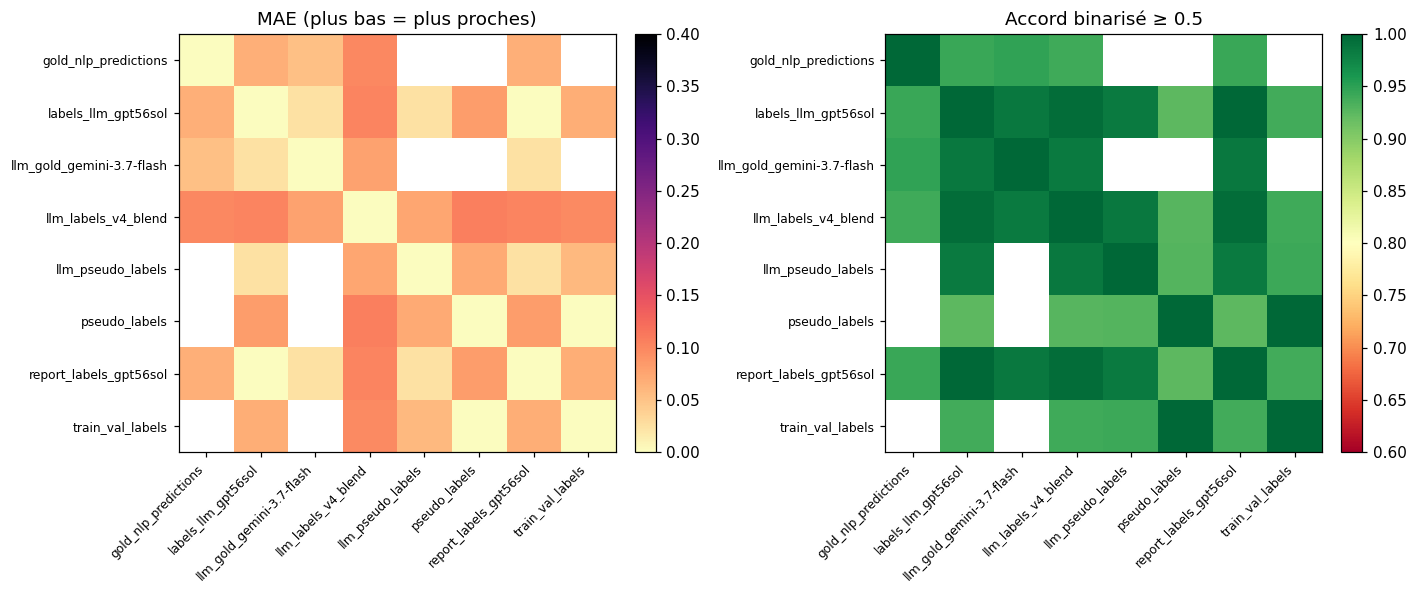

In [10]:
names = list(sets)


def pair_metrics(a: pd.DataFrame, b: pd.DataFrame):
    common = sorted(set(a.StudyInstanceUID) & set(b.StudyInstanceUID))
    if len(common) < 5:
        return None
    ia = a.set_index('StudyInstanceUID').loc[common]
    ib = b.set_index('StudyInstanceUID').loc[common]
    maes, accs, n_cell = [], [], 0
    for t in TARGETS:
        va = pd.to_numeric(ia[t], errors='coerce')
        vb = pd.to_numeric(ib[t], errors='coerce')
        m = va.notna() & vb.notna()
        if not m.any():
            continue
        maes.append(float((va[m] - vb[m]).abs().mean()))
        ba = (va[m] >= 0.5).astype(int)
        bb = (vb[m] >= 0.5).astype(int)
        accs.append(float((ba == bb).mean()))
        n_cell += int(m.sum())
    if not maes:
        return None
    return {
        'n_etudes': len(common),
        'n_cellules': n_cell,
        'MAE': float(np.mean(maes)),
        'accord_0.5': float(np.mean(accs)),
    }


mae_mat = pd.DataFrame(np.nan, index=names, columns=names)
acc_mat = pd.DataFrame(np.nan, index=names, columns=names)
pair_rows = []
for i, na in enumerate(names):
    mae_mat.loc[na, na] = 0.0
    acc_mat.loc[na, na] = 1.0
    for nb_ in names[i + 1:]:
        m = pair_metrics(sets[na], sets[nb_])
        if m is None:
            continue
        mae_mat.loc[na, nb_] = mae_mat.loc[nb_, na] = m['MAE']
        acc_mat.loc[na, nb_] = acc_mat.loc[nb_, na] = m['accord_0.5']
        pair_rows.append({'jeu_a': na, 'jeu_b': nb_, **m})

pair_tbl = pd.DataFrame(pair_rows).sort_values('MAE') if pair_rows else pd.DataFrame()
if len(pair_tbl):
    display(pair_tbl.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, mat, title, cmap, vmin, vmax in (
    (axes[0], mae_mat, 'MAE (plus bas = plus proches)', 'magma_r', 0, 0.4),
    (axes[1], acc_mat, 'Accord binarisé ≥ 0.5', 'RdYlGn', 0.6, 1.0),
):
    im = ax.imshow(mat.values, aspect='auto', cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(names)))
    ax.set_xticklabels(names, rotation=45, ha='right', fontsize=8)
    ax.set_yticks(range(len(names)))
    ax.set_yticklabels(names, fontsize=8)
    ax.set_title(title)
    ax.grid(False)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


## Performance vs gold (58 études)

Formule alignée sur `src/nlp/eval_gold.py` :

- **binaire + conf** : score AUC = `conf` si pred=1, `1-conf` si pred=0, `0.5` si masqué
- **soft** (probabilités) : le label lui-même est le score AUC
- **F1** : seuil 0.5, masques imputés à 0 (conservateur)
- **fidélité** : accuracy au seuil 0.5 **sur les cellules couvertes**
- **MAE** : `|pred - gold|` sur les cellules couvertes

Les CSV **sans aucun UID gold** (lexique corpus, split train/val) ne sont pas
scorables ici — leurs pendants gold-only sont `gold_nlp_predictions` (lexique)
et `llm_gold_gemini-*` (LLM).


In [11]:
def eval_vs_gold(pred: pd.DataFrame) -> pd.DataFrame:
    pred_i = pred.set_index('StudyInstanceUID')
    g = gold_y
    p = pred_i.reindex(g.index)  # étude absente = tout NaN (score 0.5)
    binary = is_binary_labels(p.reset_index())
    rows = []
    for t in TARGETS:
        y_true = g[t].astype(float).to_numpy()
        yp = pd.to_numeric(p[t], errors='coerce')
        mask = yp.notna().to_numpy()
        ccol = conf_col(p, t)
        if binary:
            if ccol:
                conf = p[ccol].fillna(0).astype(float).to_numpy()
            else:
                conf = np.where(mask, 1.0, 0.0)
            score = np.where(mask, np.where(yp.to_numpy() == 1, conf, 1.0 - conf), 0.5)
            yp_bin = np.where(mask, np.nan_to_num(yp.to_numpy(), nan=0.0), 0.0)
        else:
            score = yp.fillna(0.5).clip(0, 1).to_numpy()
            yp_bin = np.where(mask, (yp.fillna(0).to_numpy() >= 0.5).astype(float), 0.0)
        try:
            auc = float(roc_auc_score(y_true, score)) if len(np.unique(y_true)) > 1 else float('nan')
        except ValueError:
            auc = float('nan')
        f1 = float(f1_score(y_true, yp_bin, zero_division=0))
        if mask.any():
            fid = float((yp_bin[mask] == y_true[mask]).mean())
            mae = float(np.abs(np.clip(yp.fillna(0).to_numpy()[mask], 0, 1) - y_true[mask]).mean())
        else:
            fid = mae = float('nan')
        rows.append({
            'cible': t,
            'AUC': auc,
            'F1': f1,
            'fidelite': fid,
            'MAE': mae,
            'couverture': float(mask.mean()),
            'n_couvert': int(mask.sum()),
            'prev_gold': float(y_true.mean()),
            'prev_pred': float(np.nanmean(yp.to_numpy())) if mask.any() else float('nan'),
        })
    return pd.DataFrame(rows)


per_target: dict[str, pd.DataFrame] = {}
summary_rows = []
for name, df in sets.items():
    n_ov = int(df.StudyInstanceUID.isin(GOLD_UIDS).sum())
    if n_ov == 0:
        print(f'{name:40s}  pas de recouvrement gold — skip')
        continue
    st = eval_vs_gold(df)
    per_target[name] = st
    summary_rows.append({
        'jeu': name,
        'n_gold': n_ov,
        'type': 'binaire' if is_binary_labels(df[df.StudyInstanceUID.isin(GOLD_UIDS)]) else 'soft',
        'macro_AUC': float(st['AUC'].mean()),
        'macro_F1': float(st['F1'].mean()),
        'macro_fidelite': float(st['fidelite'].mean()),
        'macro_MAE': float(st['MAE'].mean()),
        'couverture': float(st['couverture'].mean()),
    })

summary = pd.DataFrame(summary_rows).sort_values('macro_AUC', ascending=False)
print('Classement par macro-AUC vs gold')
display(summary.round(3))

print('\nDétail par cible (tous les jeux scorables)')
detail = pd.concat(
    {n: st.set_index('cible')[['AUC', 'F1', 'fidelite', 'MAE', 'couverture']]
     for n, st in per_target.items()},
    axis=1,
)
display(detail.round(3))


llm_pseudo_labels                         pas de recouvrement gold — skip
pseudo_labels                             pas de recouvrement gold — skip
train_val_labels                          pas de recouvrement gold — skip
Classement par macro-AUC vs gold


,jeu,n_gold,type,macro_AUC,macro_F1,macro_fidelite,macro_MAE,couverture
3,llm_labels_v4_blend,58,soft,0.893,0.749,0.818,0.244,1.000
4,report_labels_gpt56sol,58,soft,0.835,0.748,0.816,0.178,1.000
1,labels_llm_gpt56sol,58,soft,0.835,0.748,0.816,0.178,1.000
2,llm_gold_gemini-3.7-flash,57,binaire,0.824,0.745,0.805,0.195,0.739
0,gold_nlp_predictions,58,binaire,0.762,0.651,0.760,0.240,0.476



Détail par cible (tous les jeux scorables)


gold_nlp_predictions                                   labels_llm_gpt56sol                                   llm_gold_gemini-3.7-flash  \
                                  AUC     F1 fidelite    MAE couverture                 AUC     F1 fidelite    MAE couverture                       AUC   
cible                                                                                                                                                     
ACL                             0.934  0.857    0.902  0.098      0.707               0.931  0.868    0.879  0.108        1.0                     0.903   
MCL                             0.882  0.700    0.857  0.143      0.483               0.921  0.720    0.879  0.124        1.0                     0.929   
Medial Meniscus                 0.814  0.760    0.818  0.182      0.569               0.890  0.836    0.845  0.129        1.0                     0.856   
Lateral Meniscus                0.817  0.732    0.867  0.133      0.517               0.866  0.800    0.845  0.145        1.0                     0.829   
Medial OA                       0.721  0.615    0.714  0.286      0.241               0.891  0.778    0.862  0.134        1.0                     0.857   
Lateral OA                      0.696  0.476    0.615  0.385      0.224               0.824  0.643    0.828  0.172        1.0                     0.833   
PF OA                           0.697  0.485    0.758  0.242      0.569               0.808  0.739    0.793  0.199        1.0                     0.815   
Effusion                        0.676  0.759    0.714  0.286      0.845               0.696  0.814    0.724  0.268        1.0                     0.674   
Synovitis                       0.636  0.524    0.733  0.267      0.259               0.676  0.591    0.690  0.310        1.0                     0.676   
Baker's                         0.826  0.667    0.800  0.200      0.345               0.903  0.786    0.897  0.107        1.0                     0.914   
Contusion                       0.665  0.545    0.548  0.452      0.534               0.814  0.681    0.741  0.243        1.0                     0.807   
Fracture                        0.782  0.686    0.792  0.208      0.414               0.801  0.718    0.810  0.196        1.0                     0.802   

                                                   llm_labels_v4_blend                                   report_labels_gpt56sol                         \
                     F1 fidelite    MAE couverture                 AUC     F1 fidelite    MAE couverture                    AUC     F1 fidelite    MAE   
cible                                                                                                                                                    
ACL               0.885    0.887  0.113      0.914               0.987  0.868    0.879  0.142        1.0                  0.931  0.868    0.879  0.108   
MCL               0.720    0.860  0.140      0.862               0.968  0.720    0.879  0.177        1.0                  0.921  0.720    0.879  0.124   
Medial Meniscus   0.815    0.852  0.148      0.931               0.948  0.852    0.862  0.170        1.0                  0.890  0.836    0.845  0.129   
Lateral Meniscus  0.800    0.837  0.163      0.845               0.879  0.800    0.845  0.221        1.0                  0.866  0.800    0.845  0.145   
Medial OA         0.743    0.810  0.190      0.724               0.932  0.778    0.862  0.205        1.0                  0.891  0.778    0.862  0.134   
Lateral OA        0.667    0.778  0.222      0.621               0.833  0.643    0.828  0.267        1.0                  0.824  0.643    0.828  0.172   
PF OA             0.711    0.795  0.205      0.759               0.902  0.739    0.793  0.243        1.0                  0.808  0.739    0.793  0.199   
Effusion          0.824    0.727  0.273      0.948               0.877  0.814    0.724  0.291        1.0                  0.696  0.814    0.724  0.268 

## Graphiques vs gold

1. Macro-métriques par jeu  
2. AUC par cible (barres groupées)  
3. Heatmap AUC cible × jeu  
4. Écart de prévalence (pred − gold) sur les 58 — un jeu trop positif / trop négatif se voit tout de suite


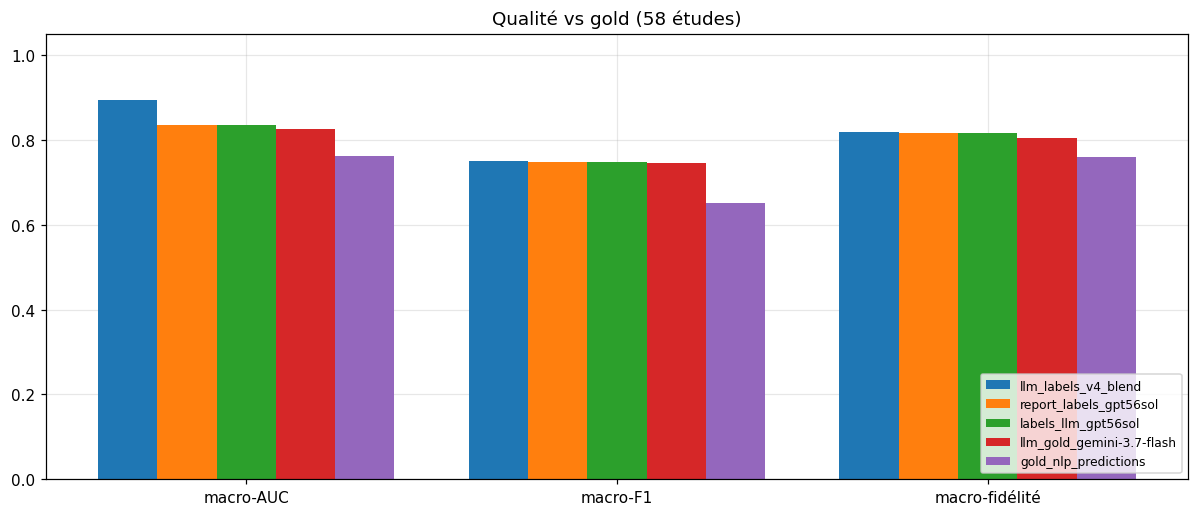

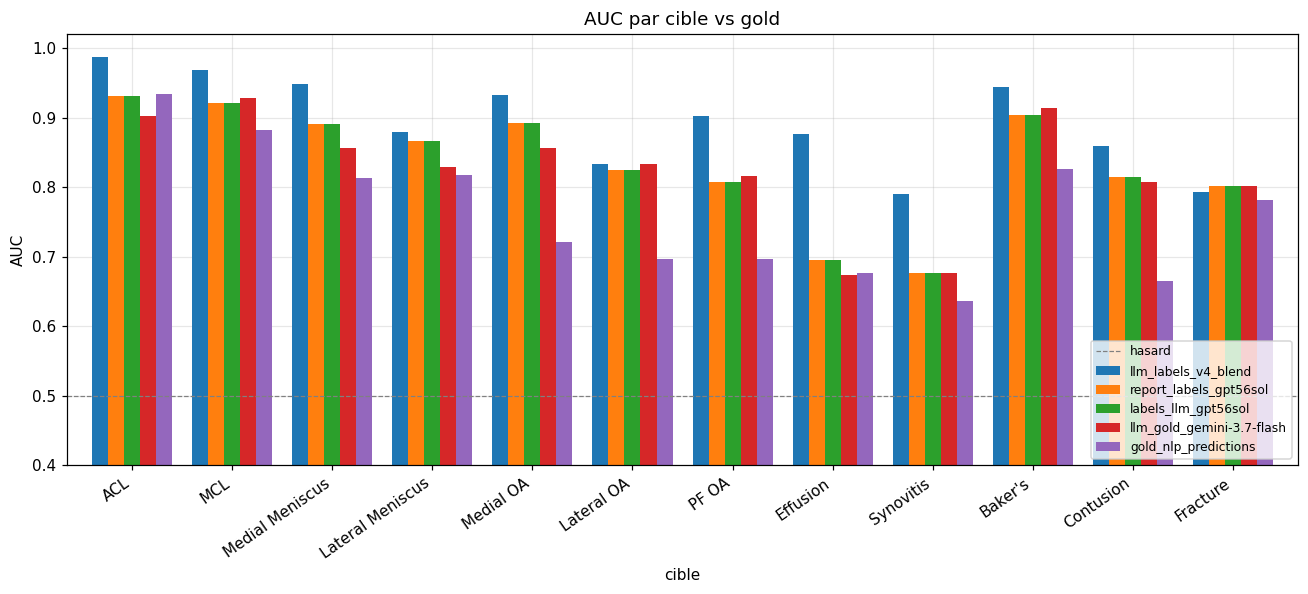

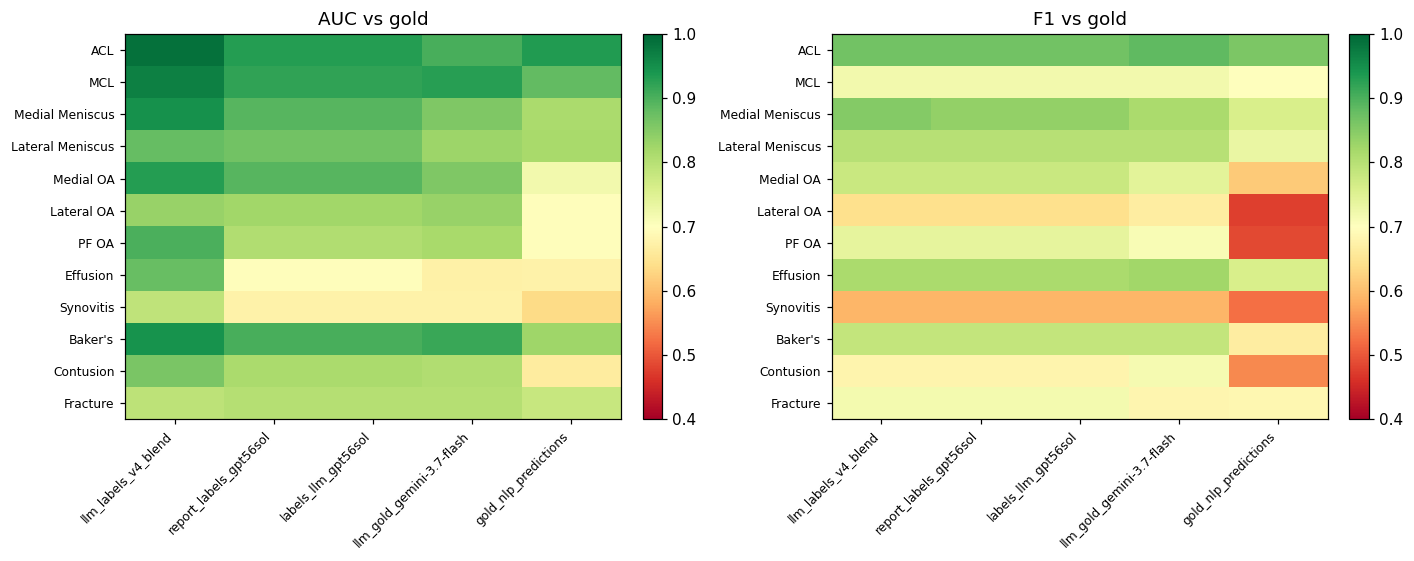

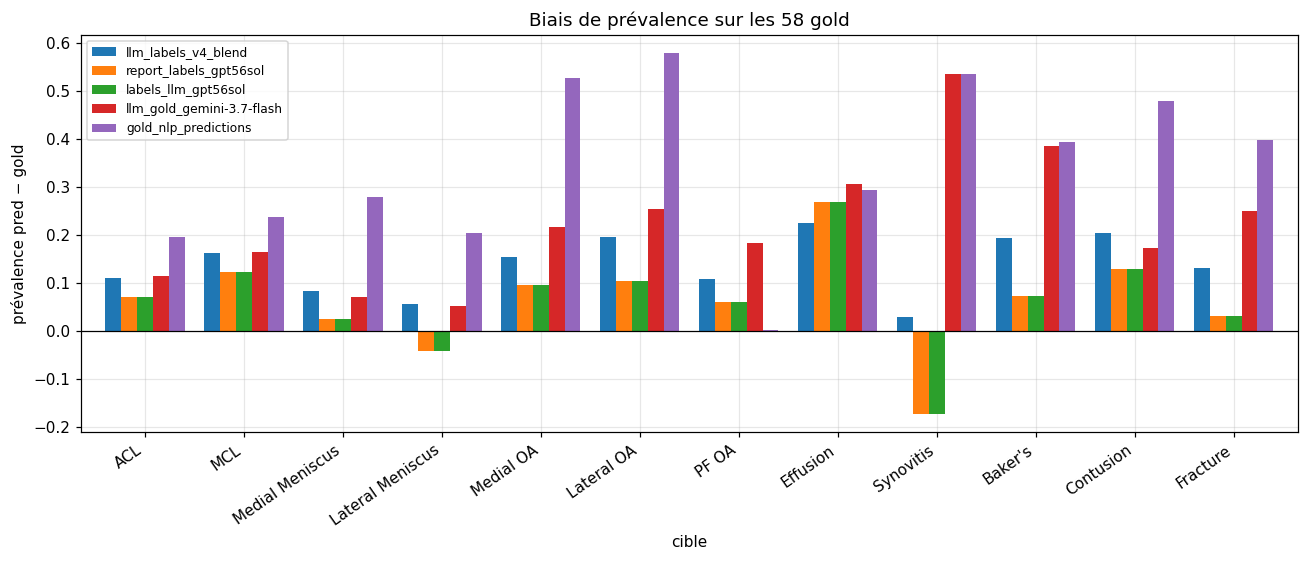

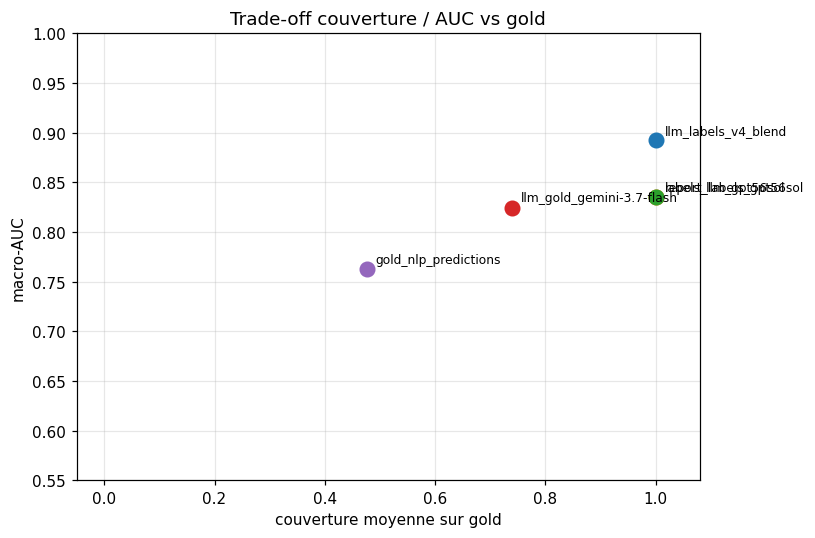

In [12]:
if not per_target:
    raise RuntimeError('aucun CSV ne recouvre les gold — rien à tracer')

order = summary['jeu'].tolist()
colors = plt.cm.tab10(np.linspace(0, 1, max(len(order), 10)))[:len(order)]

# 1. macros
fig, ax = plt.subplots(figsize=(11, 4.8))
metrics = ['macro_AUC', 'macro_F1', 'macro_fidelite']
x = np.arange(len(metrics))
width = 0.8 / len(order)
sidx = summary.set_index('jeu')
for i, name in enumerate(order):
    vals = [sidx.loc[name, m] for m in metrics]
    ax.bar(x + (i - (len(order) - 1) / 2) * width, vals, width, label=name, color=colors[i])
ax.set_xticks(x)
ax.set_xticklabels(['macro-AUC', 'macro-F1', 'macro-fidélité'])
ax.set_ylim(0, 1.05)
ax.set_title('Qualité vs gold (58 études)')
ax.legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.show()

# 2. AUC par cible
auc_wide = pd.DataFrame({n: per_target[n].set_index('cible')['AUC'] for n in order})
fig, ax = plt.subplots(figsize=(12, 5.5))
auc_wide.plot.bar(ax=ax, width=0.8, color=colors)
ax.set_ylim(0.4, 1.02)
ax.axhline(0.5, color='grey', ls='--', lw=0.8, label='hasard')
ax.set_ylabel('AUC')
ax.set_title('AUC par cible vs gold')
ax.set_xticklabels(auc_wide.index, rotation=35, ha='right')
ax.legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.show()

# 3. heatmap AUC
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
f1_wide = pd.DataFrame({n: per_target[n].set_index('cible')['F1'] for n in order})
for ax, mat, title in (
    (axes[0], auc_wide, 'AUC vs gold'),
    (axes[1], f1_wide, 'F1 vs gold'),
):
    im = ax.imshow(mat.values, aspect='auto', cmap='RdYlGn', vmin=0.4, vmax=1.0)
    ax.set_xticks(range(mat.shape[1]))
    ax.set_xticklabels(mat.columns, rotation=45, ha='right', fontsize=8)
    ax.set_yticks(range(mat.shape[0]))
    ax.set_yticklabels(mat.index, fontsize=8)
    ax.set_title(title)
    ax.grid(False)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

# 4. delta de prévalence sur gold
delta = pd.DataFrame({
    n: per_target[n].set_index('cible')['prev_pred'] - per_target[n].set_index('cible')['prev_gold']
    for n in order
})
fig, ax = plt.subplots(figsize=(12, 5.2))
delta.plot.bar(ax=ax, width=0.8, color=colors)
ax.axhline(0, color='black', lw=0.8)
ax.set_ylabel('prévalence pred − gold')
ax.set_title('Biais de prévalence sur les 58 gold')
ax.set_xticklabels(delta.index, rotation=35, ha='right')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# 5. couverture vs AUC (trade-off lexique masqué vs soft plein)
fig, ax = plt.subplots(figsize=(7.5, 5))
for i, name in enumerate(order):
    r = sidx.loc[name]
    ax.scatter(r['couverture'], r['macro_AUC'], s=90, color=colors[i], zorder=3)
    ax.annotate(name, (r['couverture'], r['macro_AUC']),
                textcoords='offset points', xytext=(6, 4), fontsize=8)
ax.set_xlabel('couverture moyenne sur gold')
ax.set_ylabel('macro-AUC')
ax.set_title('Trade-off couverture / AUC vs gold')
ax.set_xlim(-0.05, 1.08)
ax.set_ylim(0.55, 1.0)
plt.tight_layout()
plt.show()


## Split train/val (si colonne `split`)

Garde-fou : pas de chevauchement d'études. Les CSV sans `split` sont ignorés
(le loader en crée un automatiquement à l'entraînement).


In [13]:
split_files = {n: df for n, df in sets.items() if 'split' in df.columns}
if not split_files:
    print('aucun CSV avec colonne split')
else:
    for name, df in split_files.items():
        print('=' * 60)
        print(name)
        print(df['split'].value_counts().to_string())
        comp = pd.DataFrame({
            'train': df.loc[df.split == 'train', TARGETS].mean(),
            'val': df.loc[df.split == 'val', TARGETS].mean(),
        }).round(3)
        display(comp)
        tr = set(df.loc[df.split == 'train', 'StudyInstanceUID'])
        va = set(df.loc[df.split == 'val', 'StudyInstanceUID'])
        assert not (tr & va), f'fuite train/val dans {name}'
        gold_in = df.loc[df.StudyInstanceUID.isin(GOLD_UIDS), 'split'].value_counts()
        if len(gold_in):
            print('gold encore présents dans ce CSV (exclus au train par le loader) :')
            print(gold_in.to_string())
        print('pas de chevauchement train/val OK')


train_val_labels
split
train    3695
val       654


,train,val
ACL,0.244,0.245
MCL,0.153,0.150
Medial Meniscus,0.645,0.655
Lateral Meniscus,0.262,0.249
Medial OA,0.654,0.627
Lateral OA,0.616,0.588
PF OA,0.349,0.309
Effusion,0.649,0.657
Synovitis,0.648,0.661
Baker's,0.602,0.587


pas de chevauchement train/val OK
